# 05 - Real-world test with day-ahead wind forecasts from Open-Meteo

In notebooks 03 and 04 we used simulated wind noise, so that we could control the input uncertainty and see what happens. But Georgi plans
with a real weather forecast. In this notebook we test the power curve and the conformal intervals on the wind speeds that were really
forecast for 2025, one day ahead.

**Data:** historical forecasts from the Open-Meteo Previous Runs API (ECMWF IFS, 80 m, made 1 day and 3 days before each hour). They were
downloaded by the first version of notebook 03 (archived in `ZZ_ Archive/openmeteo_version/`) and saved in `data/openmeteo_forecast_2025.csv`.
We don't know the exact location of the turbine, so we guessed a location near Kavarna. Part of the forecast error therefore comes from the
wrong grid cell.

We want to answer three questions:
1. How noisy is a real forecast compared with our 1 / 5 / 10 % noise?
2. Do the intervals from the simulated noise (notebook 04) also work for real forecasts?
3. Does conformal prediction work if we calibrate it on real forecast errors? Like Georgi would do it, we calibrate on the past
   (January to August) and test on the future (September to December), classic vs. Mondrian.

Steps:
1. Load the forecasts, the turbine hours and the curve
2. Match the times
3. How good is the real forecast?
4. Intervals from the simulated noise on real forecasts
5. Intervals calibrated on real forecast errors
6. Save for the slides

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.interpolate import PchipInterpolator

HORIZON = 1                 # days ahead (Georgi plans the next day)
OTHER_HORIZON = 3           # 3 days ahead, for comparison
SHIFT_HOURS = 1             # turbine time -> UTC needs +1 h to match the forecasts (best match in the archived notebook 03)
CALIBRATION_MONTHS = range(1, 9)   # January to August for calibration, September to December for testing
ALPHA = 0.10                # allowed miss rate -> 90 % intervals
WIND_BINS = [0, 3, 5, 7, 9, 11, np.inf]   # m/s, bins of the predicted wind (same as in notebooks 03 and 04)
WIND_BIN_LABELS = ["0–3 m/s", "3–5 m/s", "5–7 m/s", "7–9 m/s", "9–11 m/s", "≥ 11 m/s"]
SYNTHETIC_LEVEL = "10 %"    # simulated noise level whose intervals we try on the real forecasts

# colors of the slide deck (taken from the title photo of the presentation)
DEEP = "#3d5687"        # deep sky: bin means, emphasis
BLUE = "#5b86bd"        # sky: wind
LIGHT_BLUE = "#9dbbe0"  # light sky: data points behind a curve
TEAL = "#6fa9b6"        # horizon teal: second series
ORANGE = "#e8673a"      # blade tip: power
GRAY = "#b9c3cd"        # light haze: context
DARK_GRAY = "#6e7f8f"   # dark haze: axes and context points
INK = "#24324a"         # text and lines

# the plots that are on the slides are saved here, at the size they have on the slide
FIGURE_DIR = "Presentation/figures"

# font of the slides: Aptos comes with PowerPoint, without PowerPoint we use Arial
APTOS_DIR = Path("/Applications/Microsoft PowerPoint.app/Contents/Resources/DFonts")
for font_file in APTOS_DIR.glob("Aptos*.ttf"):
    font_manager.fontManager.addfont(str(font_file))
if (APTOS_DIR / "Aptos.ttf").exists():
    FONT = "Aptos"
else:
    FONT = "Arial"

plt.rcParams.update({
    "font.family": FONT,
    "font.size": 10,
    "axes.labelsize": 10.5,
    "axes.labelcolor": INK,
    "axes.edgecolor": DARK_GRAY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6eaee",
    "grid.linewidth": 0.6,
    "xtick.color": DARK_GRAY,
    "ytick.color": DARK_GRAY,
    "xtick.labelcolor": INK,
    "ytick.labelcolor": INK,
    "legend.frameon": False,
    "figure.dpi": 150,    # shows the small slide figures a bit larger in the notebook
    "savefig.dpi": 220,   # resolution of the saved slide figures
    "mathtext.fontset": "custom",
    "mathtext.rm": FONT,
    "mathtext.it": FONT + ":italic",
    "mathtext.cal": FONT,   # we use no cursive math; the default cursive font of the Mac gives a font warning
})


def power_curve(table, v):
    """Power from the PCHIP curve through the bin means (same as in notebook 02).

    Below the first bin the power is 0, above the last bin it stays at the power of the last bin.

    Args:
        table: Bin table with the bin means in the columns ``v`` (m/s) and ``p`` (kW).
        v: Wind speeds in m/s.

    Returns:
        Array with the power in kW for each wind speed.
    """
    v = np.asarray(v, dtype=float)
    v_first = table["v"].iloc[0]
    v_last = table["v"].iloc[-1]
    pchip = PchipInterpolator(table["v"], table["p"])
    p = pchip(np.clip(v, v_first, v_last))
    p = np.where(v < v_first, 0.0, p)
    p = np.where(v > v_last, table["p"].iloc[-1], p)
    return p


def wind_bin(v_hat):
    """Wind bin of each hour, based on the wind we predict from.

    Args:
        v_hat: Predicted (forecast) wind speeds in m/s.

    Returns:
        Categorical with one label from ``WIND_BIN_LABELS`` per hour.
    """
    return pd.cut(np.asarray(v_hat), WIND_BINS, right=False, labels=WIND_BIN_LABELS)


def conformal_interval(errors, alpha=ALPHA):
    """Split conformal interval from signed calibration errors, with a lower and an upper margin (as in notebook 04).

    Args:
        errors: Signed errors (measured - predicted) of the calibration hours.
        alpha: Allowed miss rate, split equally between both sides (0.1 -> 90 % interval).

    Returns:
        Tuple ``(lower, upper)``: the margins in the unit of the errors.
    """
    errors = np.sort(np.asarray(errors))
    n = len(errors)
    rank_lower = int(np.clip(np.floor((n + 1) * alpha / 2), 1, n))
    rank_upper = int(np.clip(np.ceil((n + 1) * (1 - alpha / 2)), 1, n))
    return float(errors[rank_lower - 1]), float(errors[rank_upper - 1])


def mondrian_intervals(v_hat, errors):
    """Conformal interval for each bin of the predicted wind (as in notebook 04).

    Args:
        v_hat: Predicted wind speeds of the calibration hours in m/s.
        errors: Signed errors (measured - predicted) of the same hours.

    Returns:
        DataFrame with one row per bin label: number of hours ``n`` and the margins ``lower`` and ``upper``.
    """
    errors = pd.Series(np.asarray(errors))
    table = {}
    for name, group in errors.groupby(wind_bin(v_hat), observed=False):
        lower, upper = conformal_interval(group)
        table[name] = {"n": len(group), "lower": lower, "upper": upper}
    return pd.DataFrame(table).T


def margins_for(v_hat, table):
    """Look up the lower and upper margin of each hour in a table with one row per wind bin.

    Args:
        v_hat: Predicted wind speeds in m/s.
        table: Table with one row per bin label and the columns ``lower`` and ``upper``.

    Returns:
        Tuple of arrays ``(lower, upper)``, one value per hour.
    """
    labels = pd.Series(wind_bin(v_hat)).astype(str)
    return table.loc[labels, "lower"].to_numpy(), table.loc[labels, "upper"].to_numpy()


def evaluate(v_hat, errors, lower, upper):
    """Share of hours inside the interval (overall and per wind bin) and the mean width of the interval.

    Args:
        v_hat: Predicted wind speeds in m/s.
        errors: Signed errors (measured - predicted).
        lower: Lower margin of each hour.
        upper: Upper margin of each hour.

    Returns:
        Dict with ``coverage``, ``mean width`` and the coverage per wind bin.
    """
    errors = np.asarray(errors)
    inside = pd.Series((errors >= lower) & (errors <= upper))
    result = {"coverage": inside.mean(), "mean width": np.mean(upper - lower)}
    result.update(inside.groupby(wind_bin(v_hat), observed=False).mean().to_dict())
    return result

def style_power_axes(ax, xlabel="wind speed v [m/s]"):
    """Axes of the wind speed vs. power plots, the same on every slide.

    Args:
        ax: Matplotlib axes.
        xlabel: Label of the x axis.
    """
    ax.set_xlim(0, 17)
    ax.set_xticks([0, 5, 10, 15])
    ax.set_ylim(-60, 1150)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("power P [kW]")
    ax.grid(axis="x", visible=False)

def split_legend(ax, point_labels):
    """Two legends: the band and the lines at the top left, the data points at the bottom right.

    Args:
        ax: Matplotlib axes with labelled bands, lines and points.
        point_labels: Labels of the data points, e.g. ``["inside", "outside"]``.
    """
    handles, labels = ax.get_legend_handles_labels()
    line_handles = []
    line_labels = []
    point_handles = []
    point_names = []
    for handle, label in zip(handles, labels):
        if label in point_labels:
            point_handles.append(handle)
            point_names.append(label)
        else:
            line_handles.append(handle)
            line_labels.append(label)
    top_left = ax.legend(line_handles, line_labels, loc="upper left", fontsize=9.5)
    ax.add_artist(top_left)   # keep the first legend, the second legend call would replace it otherwise
    ax.legend(point_handles, point_names, loc="lower right", fontsize=9.5, markerscale=2)


def coverage_bars(ax, series, colors, names):
    """Grouped bars of the share of hours inside the interval per wind bin, with a dashed line at 90 %.

    Args:
        ax: Matplotlib axes.
        series: List with the coverage per wind bin (fractions), one entry per method.
        colors: One color per method.
        names: One legend name per method.
    """
    x = np.arange(len(WIND_BIN_LABELS))
    width = 0.8 / len(series)
    for k in range(len(series)):
        offset = (k - (len(series) - 1) / 2) * width
        ax.bar(x + offset, 100 * np.asarray(series[k]), width=width * 0.92, color=colors[k], label=names[k])
    ax.axhline(100 * (1 - ALPHA), color=INK, ls="--", lw=1)
    if len(series) > 1:
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(series), fontsize=9.5)
    short_labels = []
    for label in WIND_BIN_LABELS:
        short_labels.append(label.replace(" m/s", ""))   # "0–3 m/s" -> "0–3", so the labels fit under the small chart
    ax.set_xticks(x, short_labels)
    ax.set_ylim(40, 104)
    ax.set_xlabel("predicted wind [m/s]")
    ax.set_ylabel("hours inside [%]")
    ax.grid(axis="x", visible=False)

## 1. Forecasts, turbine hours and curve

The power curve is the one from notebook 02 (fitted on the training hours). This time we use all available turbine hours (data ok and
turbine running, cleaning rules 1-3). A real forecast also has to deal with gusts and reduced output, so we don't apply the outlier rule 4 here.
One small problem: the curve has seen 80 % of the cleaned hours of this year. But its own error (about 24 kW) is tiny compared with the
forecast error, so this hardly matters.

In [2]:
bins = pd.read_csv("data/power_curve_bins.csv")
forecasts = pd.read_csv("data/openmeteo_forecast_2025.csv", parse_dates=["time_utc"])
hours = pd.read_csv("data/scada_hours.csv", parse_dates=["time_local"])
hours = hours[hours["available"]].copy()
print(f"{len(forecasts)} forecast hours, {len(hours)} available turbine hours")

8760 forecast hours, 8542 available turbine hours


## 2. Match the times

The turbine uses local time with daylight saving, Open-Meteo uses UTC. We convert the turbine times to UTC and shift them by +1 h.
This shift matched the forecasts best in the archived notebook 03 (the time stamp of the turbine probably marks the start of the hour).

In [3]:
# local time -> UTC (the ambiguous and missing daylight saving hours become NaT), then the +1 h shift
time_utc = hours["time_local"].dt.tz_localize("Europe/Sofia", ambiguous="NaT", nonexistent="NaT")
time_utc = time_utc.dt.tz_convert("UTC").dt.tz_localize(None)
hours["time_utc"] = time_utc + pd.Timedelta(hours=SHIFT_HOURS)

# keep the hours that have a forecast
data = hours.dropna(subset=["time_utc"]).merge(forecasts, on="time_utc")

# prediction and signed error for the 1 day and the 3 day forecast
for h in [HORIZON, OTHER_HORIZON]:
    data[f"p_hat_d{h}"] = power_curve(bins, data[f"v_d{h}"])
    data[f"error_d{h}"] = data["p"] - data[f"p_hat_d{h}"]

# January to August for calibration, September to December for testing
data["period"] = "test"
data.loc[data["time_utc"].dt.month.isin(CALIBRATION_MONTHS), "period"] = "calibration"
print(f"{len(data)} hours with measurement and forecast:", data["period"].value_counts().to_dict())

8541 hours with measurement and forecast: {'calibration': 5651, 'test': 2890}


## 3. How good is the real forecast?

Three plots, from the wind to the power: the forecast wind against the measured wind (left), the measured power against the forecast
wind with our curve as the prediction (middle) and the error of the power prediction against the forecast wind (right).
The real cone on the left is much wider than with our 10 % noise, and it is shifted: on average the forecast is too windy.
In the middle plot the vertical distance from each hour to the curve is its error in the right plot. On the steep part most hours lie
below the curve, because the forecast wind is too high and so the curve predicts too much power.

,wind RMSE [m/s],wind RMSE / mean wind,wind bias [m/s],power RMSE [kW],power RMSE / mean power
forecast 1 day ahead,1.94,37%,+0.70,209,85%
forecast 3 days ahead,2.26,43%,+0.60,243,99%
simulated wind ± 1%,-,1%,-,8,3%
simulated wind ± 5%,-,6%,-,41,16%
simulated wind ± 10%,-,12%,-,80,32%


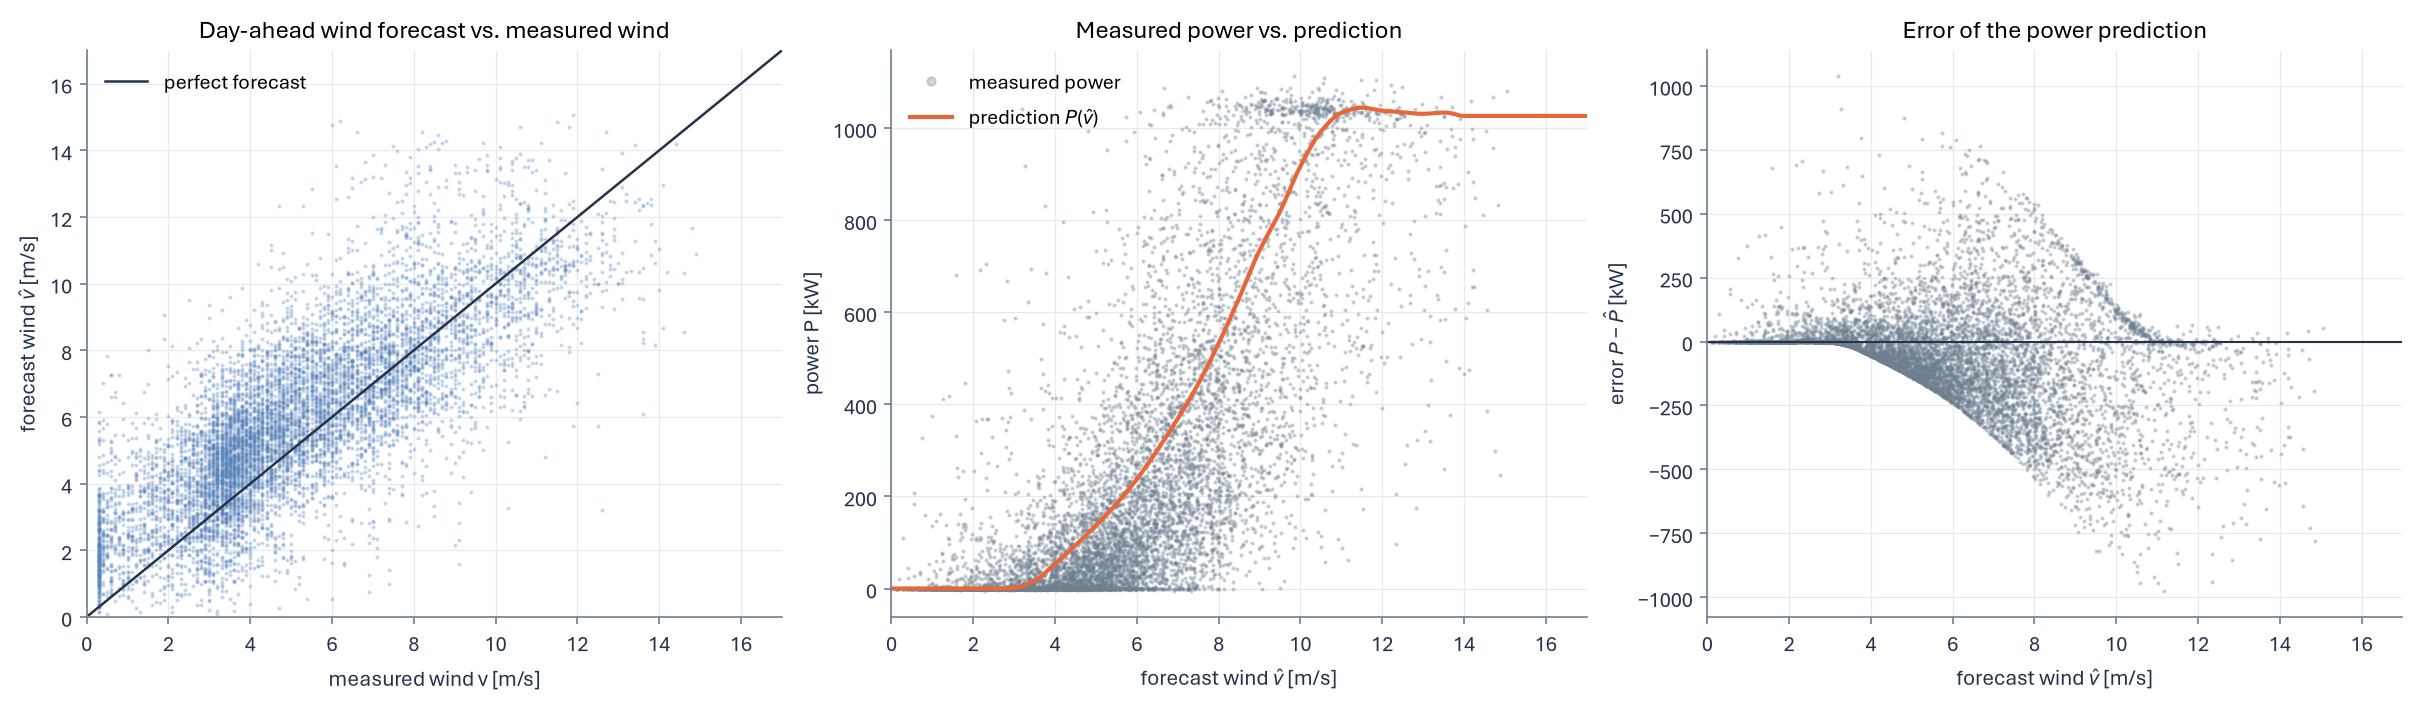

In [4]:
def rmse(err):
    """Root mean squared error.

    Args:
        err: Errors.

    Returns:
        The RMSE, in the unit of ``err``.
    """
    return float(np.sqrt(np.mean(np.square(err))))


# errors of the real forecasts for both horizons
rows = {}
for h in [HORIZON, OTHER_HORIZON]:
    if h == 1:
        name = "forecast 1 day ahead"
    else:
        name = f"forecast {h} days ahead"
    dv = data[f"v_d{h}"] - data["v"]
    rows[name] = {"wind RMSE [m/s]": rmse(dv),
                  "wind RMSE / mean wind": rmse(dv) / data["v"].mean(),
                  "wind bias [m/s]": dv.mean(),
                  "power RMSE [kW]": rmse(data[f"error_d{h}"]),
                  "power RMSE / mean power": rmse(data[f"error_d{h}"]) / data["p"].mean()}

# our simulated noise levels from notebook 03 for comparison
noise = pd.read_csv("data/noise_errors.csv", index_col="noise")
for label, row in noise.iterrows():
    rows[f"simulated {label}"] = {"wind RMSE / mean wind": row["wind RMSE"],
                                  "power RMSE [kW]": row["power RMSE [kW]"],
                                  "power RMSE / mean power": row["power RMSE"]}
quality = pd.DataFrame(rows).T
display(quality.style.format({"wind RMSE [m/s]": "{:.2f}", "wind RMSE / mean wind": "{:.0%}", "wind bias [m/s]": "{:+.2f}",
                              "power RMSE [kW]": "{:.0f}", "power RMSE / mean power": "{:.0%}"}, na_rep="-"))

# forecast vs. measured wind (left), measured power around the prediction (middle), power error vs. forecast wind (right)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")
ax1.plot(data["v"], data[f"v_d{HORIZON}"], ".", ms=2, color=BLUE, alpha=0.25)
ax1.plot([0, 17], [0, 17], color=INK, lw=1.2, label="perfect forecast")
ax1.set(title="Day-ahead wind forecast vs. measured wind", xlabel="measured wind v [m/s]",
        ylabel=r"forecast wind $\hat{v}$ [m/s]", xlim=(0, 17), ylim=(0, 17))
ax1.legend(loc="upper left")

# measured power against the forecast wind, with our prediction curve
v_grid = np.linspace(0, 17, 500)
ax2.plot(data[f"v_d{HORIZON}"], data["p"], ".", ms=2, color=DARK_GRAY, alpha=0.3, label="measured power")
ax2.plot(v_grid, power_curve(bins, v_grid), color=ORANGE, lw=2, label=r"prediction $P(\hat{v})$")
ax2.set(title="Measured power vs. prediction", xlabel=r"forecast wind $\hat{v}$ [m/s]", ylabel="power P [kW]", xlim=(0, 17))
ax2.legend(loc="upper left", markerscale=4)

ax3.plot(data[f"v_d{HORIZON}"], data[f"error_d{HORIZON}"], ".", ms=2, color=DARK_GRAY, alpha=0.3)
ax3.axhline(0, color=INK, lw=1)
ax3.set(title="Error of the power prediction", xlabel=r"forecast wind $\hat{v}$ [m/s]", ylabel=r"error $P - \hat{P}$ [kW]",
        xlim=(0, 17))
plt.show()

## 4. Intervals from the simulated noise on real forecasts

What happens if Georgi uses the intervals we calibrated on 10 % simulated noise (notebook 04) for the real day-ahead forecast?
The 90 % only holds for hours that behave like the calibration hours, and the real forecast hours don't: their errors are much larger.

In [5]:
# classic and Mondrian intervals from notebook 04 (10 % noise)
classic_synthetic = pd.read_csv("data/conformal_margins.csv", index_col="noise").loc[SYNTHETIC_LEVEL]
mondrian_synthetic = pd.read_csv("data/mondrian_margins.csv", index_col=["noise", "wind_bin"]).loc[SYNTHETIC_LEVEL]

# apply them to all real forecast hours
v_hat = data[f"v_d{HORIZON}"]
err = data[f"error_d{HORIZON}"]
results = {}
lower = np.full(len(err), classic_synthetic["lower"])
upper = np.full(len(err), classic_synthetic["upper"])
results[("simulated 10 % noise", "classic")] = evaluate(v_hat, err, lower, upper)
lower, upper = margins_for(v_hat, mondrian_synthetic)
results[("simulated 10 % noise", "mondrian")] = evaluate(v_hat, err, lower, upper)

percent_format = {"coverage": "{:.0%}", "mean width": "{:.0f} kW"}
for name in WIND_BIN_LABELS:
    percent_format[name] = "{:.0%}"
pd.DataFrame(results).T.style.format(percent_format)

## 5. Intervals calibrated on real forecast errors

Now we give the method what it needs: calibration hours with real forecast errors. We calibrate on January to August and test on
September to December, so we only test on hours that come after the calibration hours. This is harder than a random split, because
autumn and winter are windier than the calibration months. Again classic (one interval) vs. Mondrian (one interval per bin of the
forecast wind).

The last three plots show the test months: the errors with both intervals, the same intervals not normalized, as a band around
the curve in kW, and the share of test hours inside the interval per bin.

In [6]:
calibration = data[data["period"] == "calibration"]
test = data[data["period"] == "test"]

# calibrate on January-August, test on September-December, for both horizons
real_mondrian = {}
for h in [HORIZON, OTHER_HORIZON]:
    if h == 1:
        scenario = "real, 1 day ahead"
    else:
        scenario = f"real, {h} days ahead"
    v_cal = calibration[f"v_d{h}"]
    e_cal = calibration[f"error_d{h}"]
    v_test = test[f"v_d{h}"]
    e_test = test[f"error_d{h}"]

    # classic: one interval from all calibration hours
    lower, upper = conformal_interval(e_cal)
    row = evaluate(v_test, e_test, np.full(len(e_test), lower), np.full(len(e_test), upper))
    row["lower"] = lower
    row["upper"] = upper
    results[(scenario, "classic")] = row

    # Mondrian: one interval per bin of the forecast wind
    real_mondrian[h] = mondrian_intervals(v_cal, e_cal)
    lower_test, upper_test = margins_for(v_test, real_mondrian[h])
    results[(scenario, "mondrian")] = evaluate(v_test, e_test, lower_test, upper_test)

summary = pd.DataFrame(results).T
summary.index.names = ["scenario", "method"]
summary_format = {"coverage": "{:.0%}", "mean width": "{:.0f} kW", "lower": "{:+.0f} kW", "upper": "{:+.0f} kW"}
for name in WIND_BIN_LABELS:
    summary_format[name] = "{:.0%}"
display(summary.style.format(summary_format, na_rep="-"))

real_mondrian[HORIZON].style.format({"n": "{:.0f}", "lower": "{:+.0f} kW", "upper": "{:+.0f} kW"}) \
    .set_caption("Mondrian intervals from the real day-ahead errors (January to August)")

,n,lower,upper
0–3 m/s,844,-1 kW,+134 kW
3–5 m/s,1470,-113 kW,+169 kW
5–7 m/s,1633,-252 kW,+354 kW
7–9 m/s,1081,-463 kW,+381 kW
9–11 m/s,510,-619 kW,+264 kW
≥ 11 m/s,113,-739 kW,+12 kW


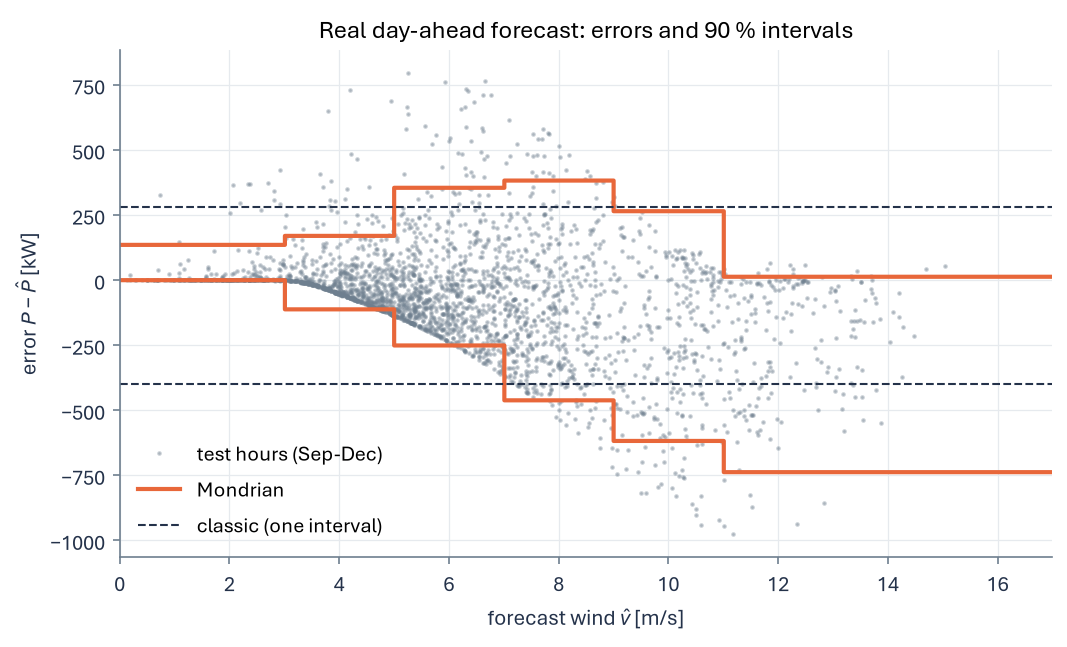

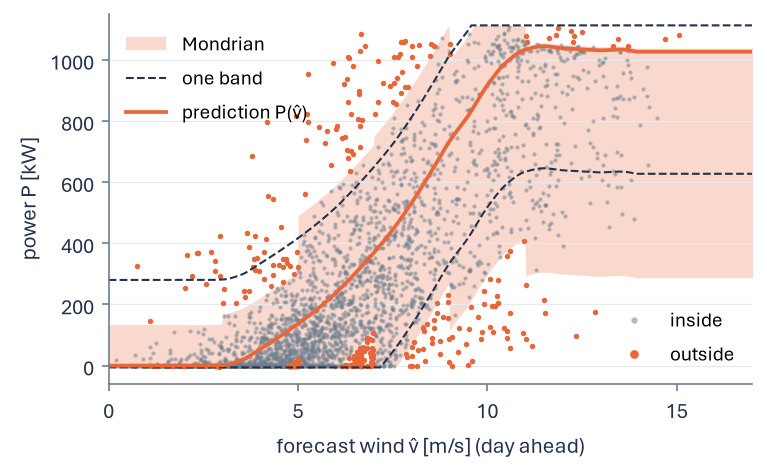

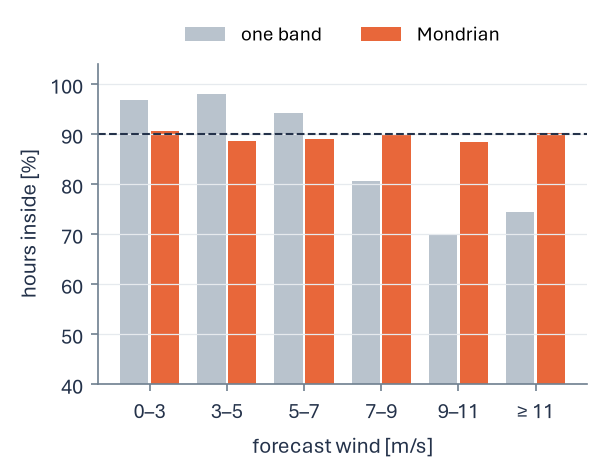

In [7]:
# test months: errors with both intervals (residual view)
v_grid = np.linspace(0, 17, 1000)
scenario = "real, 1 day ahead"
lower, upper = margins_for(v_grid, real_mondrian[HORIZON])
classic_lower = summary.loc[(scenario, "classic"), "lower"]
classic_upper = summary.loc[(scenario, "classic"), "upper"]

fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
ax.plot(test[f"v_d{HORIZON}"], test[f"error_d{HORIZON}"], ".", ms=2.5, color=DARK_GRAY, alpha=0.35, label="test hours (Sep-Dec)")
ax.step(v_grid, lower, where="post", color=ORANGE, lw=2, label="Mondrian")
ax.step(v_grid, upper, where="post", color=ORANGE, lw=2)
ax.axhline(classic_lower, color=INK, lw=1, ls="--", label="classic (one interval)")
ax.axhline(classic_upper, color=INK, lw=1, ls="--")
ax.set(title="Real day-ahead forecast: errors and 90 % intervals", xlabel=r"forecast wind $\hat{v}$ [m/s]",
       ylabel=r"error $P - \hat{P}$ [kW]", xlim=(0, 17))
ax.legend(loc="lower left")
plt.show()

# the same intervals not normalized: bands around the curve, cut at the smallest and largest power of the calibration months
# (slide 20, left); a test hour is inside if its error is between the Mondrian margins of its own bin
p_grid = power_curve(bins, v_grid)
p_min = calibration["p"].min()
p_max = calibration["p"].max()
lower_hour, upper_hour = margins_for(test[f"v_d{HORIZON}"], real_mondrian[HORIZON])
inside = (test[f"error_d{HORIZON}"] >= lower_hour) & (test[f"error_d{HORIZON}"] <= upper_hour)
fig, ax = plt.subplots(figsize=(5.0, 3.05), layout="constrained")
ax.fill_between(v_grid, np.clip(p_grid + lower, p_min, p_max), np.clip(p_grid + upper, p_min, p_max), color=ORANGE, alpha=0.25,
                lw=0, label="Mondrian")
ax.plot(test[f"v_d{HORIZON}"][inside], test["p"][inside], ".", ms=2.2, color=DARK_GRAY, alpha=0.4, rasterized=True, label="inside")
ax.plot(test[f"v_d{HORIZON}"][~inside], test["p"][~inside], ".", ms=3.2, color=ORANGE, rasterized=True, label="outside")
ax.plot(v_grid, np.clip(p_grid + classic_lower, p_min, p_max), color=INK, lw=1, ls="--", label="one band")
ax.plot(v_grid, np.clip(p_grid + classic_upper, p_min, p_max), color=INK, lw=1, ls="--")
ax.plot(v_grid, p_grid, color=ORANGE, lw=1.8, label="prediction P(v̂)")
style_power_axes(ax, xlabel="forecast wind v̂ [m/s] (day ahead)")
split_legend(ax, ["inside", "outside"])
fig.savefig(f"{FIGURE_DIR}/real_forecast_band.png", transparent=False, facecolor="white")
plt.show()

# share of test hours inside the interval per bin (slide 20, right)
classic_per_bin = summary.loc[(scenario, "classic"), WIND_BIN_LABELS].astype(float)
mondrian_per_bin = summary.loc[(scenario, "mondrian"), WIND_BIN_LABELS].astype(float)
fig, ax = plt.subplots(figsize=(3.9, 3.05), layout="constrained")
coverage_bars(ax, [classic_per_bin, mondrian_per_bin], [GRAY, ORANGE], ["one band", "Mondrian"])
ax.set_xlabel("forecast wind [m/s]")
fig.savefig(f"{FIGURE_DIR}/coverage_real.png", transparent=False, facecolor="white")
plt.show()

## 6. Save for the slides

We save the hourly table (forecast wind, prediction, error, calibration or test), the summary of all scenarios and the Mondrian intervals
from the real day-ahead errors.

In [8]:
columns = ["time_utc", "v", "p", f"v_d{HORIZON}", f"p_hat_d{HORIZON}", f"error_d{HORIZON}", "period"]
data[columns].to_csv("data/real_forecast_test.csv", index=False)
summary.to_csv("data/real_forecast_summary.csv")
real_mondrian[HORIZON].rename_axis("wind_bin").to_csv("data/real_forecast_mondrian.csv")
quality.rename_axis("source").to_csv("data/real_forecast_quality.csv")
print("saved real_forecast_test.csv, real_forecast_summary.csv, real_forecast_mondrian.csv, real_forecast_quality.csv")

saved real_forecast_test.csv, real_forecast_summary.csv, real_forecast_mondrian.csv, real_forecast_quality.csv


## Takeaways

- **Real forecasts are much noisier than our simulation.** The day-ahead wind forecast has an RMSE of 1.9 m/s (37 % of the mean wind,
  our strongest noise was 12 %) and is too windy by 0.7 m/s on average. Through the power curve this becomes 209 kW (85 % of the mean
  power), so the same amplification as in notebook 03.
- **Intervals calibrated on the simulated noise don't work:** only 62 % (classic) and 52 % (Mondrian) of the real hours are inside.
  The 90 % needs calibration hours that behave like the new hours, and the simulated hours don't.
- **Calibrated on real forecast errors, conformal prediction works again,** also on later months it has never seen (calibration
  January to August, test September to December): 89 % of the day-ahead test hours are inside for both methods.
- **Mondrian also holds per bin:** 88-91 % in every bin of the forecast wind (classic: 70-98 %), and the interval is 18 % narrower
  (559 instead of 679 kW on average). For 3 days ahead: 91 % / 89 % inside, with intervals of 689 / 801 kW.
- The intervals for a real forecast are wide: at 7-9 m/s forecast wind the day-ahead interval goes from -463 to +381 kW around the
  prediction, at rated power from -739 to +12 kW. An hourly power forecast one day ahead is very uncertain, and conformal prediction
  tells us how uncertain.
- **Answer to Georgi:** his predictions fail so often because the wind forecast is off by about a third, and the steep power curve
  multiplies this error. Conformal intervals calibrated on his own past forecast errors hold for about 90 % of the hours, also in later months.

**Limitations:** only one year of data. The turbine location is a guess (the wrong grid cell adds error). Autumn and winter are windier than
the calibration months. Intervals for the daily energy would be much narrower than for single hours